# 01 · Load and explore: wild animal road collisions, Catalonia

Source: Mossos d'Esquadra via Transparència Catalunya, dataset `ght6-dqp5`  
API: https://analisi.transparenciacatalunya.cat/resource/ght6-dqp5.json

Goal today: load the data into pandas, report row count and columns, and count wild boar rows per year.

In [42]:
import pandas as pd
import matplotlib.pyplot as plt

In [9]:
df = pd.read_json("https://analisi.transparenciacatalunya.cat/resource/ght6-dqp5.json?$limit=30000")
df.shape

(29486, 19)

The API returns only 1,000 rows by default, so $limit=30000 loads all 29,486 rows.

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29486 entries, 0 to 29485
Data columns (total 19 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   any_inici_actuacio                29486 non-null  object 
 1   hora_inici_actuacio               29485 non-null  object 
 2   data_inici_actuacio               29485 non-null  object 
 3   provincia_actuacio                29485 non-null  object 
 4   regio_policial_actuacio           29485 non-null  object 
 5   comarca_actuacio                  29485 non-null  object 
 6   codi_comarca                      29485 non-null  float64
 7   municipi_actuacio                 29485 non-null  object 
 8   codi_municipi                     29485 non-null  float64
 9   via_urbana_interurbana            29485 non-null  object 
 10  via_actuacio                      29485 non-null  object 
 11  numero_punt_quilometric_actuacio  29485 non-null  float64
 12  esta

The injury columns (ferits_lleus, ferits_greus, morts) count people, not animals. A blank means 0.

In [11]:
df.head()

,any_inici_actuacio,hora_inici_actuacio,data_inici_actuacio,provincia_actuacio,regio_policial_actuacio,comarca_actuacio,codi_comarca,municipi_actuacio,codi_municipi,via_urbana_interurbana,via_actuacio,numero_punt_quilometric_actuacio,estat_accident,valoracio_accident,animal_accident,ilesos,ferits_lleus,morts,ferits_greus
0,2025,00:00:04,2025-05-04T00:00:00.000,Barcelona,RP Metropolitana Nord,Vallès Oriental,41.0,"Garriga, la",80885.0,Interurbana,C-17,29.5,Accident il·lès,Es desconeix si es realitzava una acció de caç...,Ungulat (porc senglar),2.0,NaN,NaN,NaN
1,2025,00:00:13,2025-07-02T00:00:00.000,Tarragona,RP Terres de l'Ebre,Montsià,22.0,Alcanar,430043.0,Interurbana,N-340,1059.0,Accident il·lès,Es desconeix si es realitzava una acció de caç...,Ungulat (porc senglar),1.0,NaN,NaN,NaN
2,2025,00:00:24,2025-06-26T00:00:00.000,Barcelona,RP Metropolitana Nord,Vallès Occidental,40.0,Sabadell,81878.0,Interurbana,NA,0.5,Accident il·lès,No a conseqüència de l'acció de caça. Via no s...,Ungulat (porc senglar),1.0,NaN,NaN,NaN
3,2025,00:00:26,2025-11-24T00:00:00.000,Girona,RP Girona,Selva,34.0,Santa Coloma de Farners,171805.0,Interurbana,C-152,1.3,Accident il·lès,Es desconeix si es realitzava una acció de caç...,Ungulat (porc senglar),1.0,NaN,NaN,NaN
4,2025,00:00:28,2025-08-08T00:00:00.000,Girona,RP Girona,Alt Empordà,2.0,Navata,171117.0,Interurbana,N-260,46.7,Accident il·lès,No a conseqüència de l'acció de caça. Via no s...,Ungulat (porc senglar),1.0,NaN,NaN,NaN


In [17]:
df["any_inici_actuacio"].value_counts()

any_inici_actuacio
2022    6114
2025    6003
2024    5822
2023    5742
2026    2943
2021    2861
Name: count, dtype: int64

In [13]:
df["animal_accident"].value_counts()

animal_accident
Ungulat (porc senglar)                     19038
Cèrvids (cabirol, isard, cérvol, daina)     7669
Domèstic (gos,gat)                          1342
Salvatge (guineu, teixó, gineta)             795
No identificat                               315
Boví (vaca, ovella)                           83
Altres                                        82
Equí (cavall, ruc)                            69
Altres (voltor, àliga, rapinyaires)           66
Aus (voltor, àliga, rapinyaires)              26
Name: count, dtype: int64

The exact label for wild boar is Ungulat (porc senglar). Some bird labels are duplicated.

In [23]:
df = df[df["any_inici_actuacio"] != "Total"]
df.shape

(29485, 19)

The year column had a “Total” summary row. It’s removed, which leaves 29,485 rows.

In [25]:
df["any_inici_actuacio"] = df["any_inici_actuacio"].astype(int)
df.dtypes

any_inici_actuacio                    int64
hora_inici_actuacio                  object
data_inici_actuacio                  object
provincia_actuacio                   object
regio_policial_actuacio              object
comarca_actuacio                     object
codi_comarca                        float64
municipi_actuacio                    object
codi_municipi                       float64
via_urbana_interurbana               object
via_actuacio                         object
numero_punt_quilometric_actuacio    float64
estat_accident                       object
valoracio_accident                   object
animal_accident                      object
ilesos                              float64
ferits_lleus                        float64
morts                               float64
ferits_greus                        float64
dtype: object

In [27]:
boar = df[df["animal_accident"] == "Ungulat (porc senglar)"]
boar.shape

(19038, 19)

In [37]:
boar["any_inici_actuacio"].value_counts().sort_index()

any_inici_actuacio
2021    2120
2022    4288
2023    3697
2024    3638
2025    3829
2026    1466
Name: count, dtype: int64

2026 stops in June, and 2021 looks low (checked below).

In [38]:
df["data_inici_actuacio"] = pd.to_datetime(df["data_inici_actuacio"])
df.dtypes

any_inici_actuacio                           int64
hora_inici_actuacio                         object
data_inici_actuacio                 datetime64[ns]
provincia_actuacio                          object
regio_policial_actuacio                     object
comarca_actuacio                            object
codi_comarca                               float64
municipi_actuacio                           object
codi_municipi                              float64
via_urbana_interurbana                      object
via_actuacio                                object
numero_punt_quilometric_actuacio           float64
estat_accident                              object
valoracio_accident                          object
animal_accident                             object
ilesos                                     float64
ferits_lleus                               float64
morts                                      float64
ferits_greus                               float64
dtype: object

In [39]:
df["mes"] = df["data_inici_actuacio"].dt.month
df[["data_inici_actuacio", "mes"]].head()

,data_inici_actuacio,mes
0,2025-05-04,5
1,2025-07-02,7
2,2025-06-26,6
3,2025-11-24,11
4,2025-08-08,8


In [40]:
boar = df[df["animal_accident"] == "Ungulat (porc senglar)"]
boar_2021 = boar[boar["any_inici_actuacio"] == 2021]
boar_2021["mes"].value_counts().sort_index()

mes
1      51
2      45
3      32
4      25
5      31
6      21
7      34
8      55
9     306
10    494
11    512
12    514
Name: count, dtype: int64

In [41]:
boar_2022 = boar[boar["any_inici_actuacio"] == 2022]
boar_2022["mes"].value_counts().sort_index()

mes
1     370
2     322
3     245
4     229
5     205
6     199
7     229
8     265
9     314
10    562
11    777
12    571
Name: count, dtype: int64

### 2021 is not comparable before September
2021: From January to August 2021 there are only 21 to 55 boar collisions a month, then 306 in September and around 500 a month to December. January to August 2022 has 199 to 370 a month, and September matches in both years (306 vs 314), so the jump is likely a change in recording from September 2021, not fewer collisions. Monthly analysis starts in September 2021; yearly totals use 2022 to 2025 only.

In [43]:
monthly = (
    boar.set_index("data_inici_actuacio")
        .resample("MS")
        .size()
)
monthly = monthly[monthly.index >= "2021-09-01"]

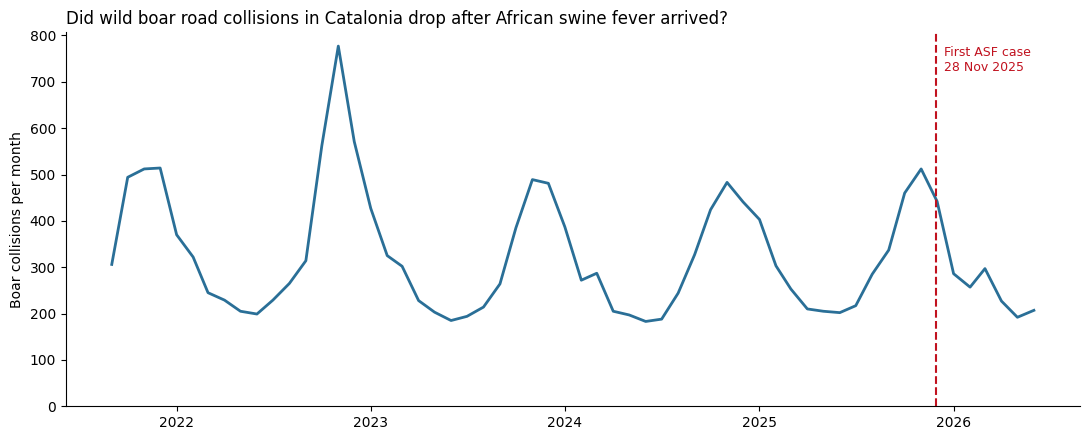

In [44]:
fig, ax = plt.subplots(figsize=(11, 4.5))

ax.plot(monthly.index, monthly.values, color="#2a6f97", linewidth=2)
ax.axvline(pd.Timestamp("2025-11-28"), color="#c1121f", linestyle="--", linewidth=1.5)
ax.text(pd.Timestamp("2025-11-28"), monthly.max(), "  First ASF case\n  28 Nov 2025",
        color="#c1121f", va="top", fontsize=9)
ax.set_title("Did wild boar road collisions in Catalonia drop after African swine fever arrived?",
             loc="left", fontsize=12)
ax.set_ylabel("Boar collisions per month")
ax.set_ylim(bottom=0)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()